# Fase 7 — Evaluación comparativa de estrategias

## Objetivo
Comparar el rendimiento de las 6 configuraciones de PPO (3 feature sets × con/sin cash) con 20 seeds cada una, contra benchmarks pasivos, usando métricas ajustadas por riesgo y análisis por régimen.

## Preguntas que responde este notebook
1. ¿Supera PPO a los benchmarks en Sharpe absoluto?
2. ¿Es estable entre seeds, o tiene modos de fallo?
3. ¿Cómo se comporta en regímenes adversos?
4. ¿Aporta valor el cash como 5º activo?

## Estructura
- **§1** Setup y datos.
- **§2** Análisis agregado de los 360 runs.
- **§3** Modelos "campeones": curvas de equity y métricas.
- **§4** Comparación con benchmarks.
- **§5** Bootstrap IC95% sobre retornos diarios.
- **§6** Análisis por régimen.
- **§7** Conclusiones.

## §1 Setup y datos

Cargamos los 360 runs del CSV consolidado (Fase 6) y el dataset RL para reconstruir las curvas de equity de los modelos ganadores.

In [4]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from stable_baselines3 import PPO

from rl_env import TradingEnv, EnvConfig, FEATURE_SETS
from evaluation import (
    compute_metrics, bootstrap_sharpe, regime_analysis, benchmark_returns,
    TICKERS, TEST_START, TEST_END, WINDOW,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

MODELS_DIR = Path("../models")
DATA_PATH = Path("../data/processed/rl_dataset.csv")
RUNS_CSV = Path("../reports/all_training_runs.csv")

# Cargar dataset RL
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])

# Cargar los 360 runs
runs = pd.read_csv(RUNS_CSV)
runs["config"] = runs["features"] + runs["use_cash"].map({True: "_cash", False: ""})
runs["failed"] = runs["test_sharpe_net"] < -1.0

print(f"Dataset RL: {df.shape}")
print(f"Rango test: {TEST_START} -> {TEST_END}")
print(f"Runs totales: {len(runs)}")
print(f"Combinaciones: {runs.groupby(['config', 'mu_turnover']).size().to_dict()}")

Dataset RL: (7236, 40)
Rango test: 2024-10-22 -> 2025-10-23
Runs totales: 360
Combinaciones: {('A', 0.0): 20, ('A', 1e-05): 20, ('A', 0.0001): 20, ('A_cash', 0.0): 20, ('A_cash', 1e-05): 20, ('A_cash', 0.0001): 20, ('B', 0.0): 20, ('B', 1e-05): 20, ('B', 0.0001): 20, ('B_cash', 0.0): 20, ('B_cash', 1e-05): 20, ('B_cash', 0.0001): 20, ('C', 0.0): 20, ('C', 1e-05): 20, ('C', 0.0001): 20, ('C_cash', 0.0): 20, ('C_cash', 1e-05): 20, ('C_cash', 0.0001): 20}


## §2 Análisis agregado de los 360 runs

Cada configuración se ha entrenado con 20 seeds. Lo primero que miramos **no es la media**, sino la distribución completa. Un modelo que da Sharpe 1.8 de media pero colapsa en 1 de cada 5 seeds es un modelo **peligroso** en producción, aunque la media sea buena.

In [5]:
sub = runs[(runs["mu_turnover"] == 0.0) & (runs["leverage"] == 1.0)].copy()

summary = sub.groupby("config").agg(
    n_seeds=("seed", "count"),
    sharpe_mean=("test_sharpe_net", "mean"),
    sharpe_median=("test_sharpe_net", "median"),
    sharpe_std=("test_sharpe_net", "std"),
    sharpe_min=("test_sharpe_net", "min"),
    sharpe_max=("test_sharpe_net", "max"),
    n_failures=("failed", "sum"),
    pct_failures=("failed", lambda x: f"{x.mean()*100:.0f}%"),
    mean_return=("test_return", "mean"),
    mean_max_dd=("test_max_dd", "mean"),
).round(3)

# Ordenar: primero cash (mejor media), luego sin cash
summary = summary.sort_values("sharpe_mean", ascending=False)

print("Resumen por configuracion (20 seeds, mu=0):")
print(summary.to_string())

Resumen por configuracion (20 seeds, mu=0):
        n_seeds  sharpe_mean  sharpe_median  sharpe_std  sharpe_min  sharpe_max  n_failures pct_failures  mean_return  mean_max_dd
config                                                                                                                            
C_cash       20       1.9100         1.8620      0.1850      1.4420      2.2260           0           0%       0.2070       0.0160
B_cash       20       1.9050         1.8490      0.2100      1.6080      2.3810           0           0%       0.2280       0.0170
A_cash       20       1.8260         1.8230      0.1620      1.3630      2.3320           0           0%       0.1730       0.0130
B            20       0.8180         1.9110      2.5920     -5.3490      2.5930           4          20%       0.1120       0.1110
A            20       0.7420         1.8580      2.4630     -7.0190      2.2480           4          20%       0.1100       0.0920
C            20      -0.6570         0.

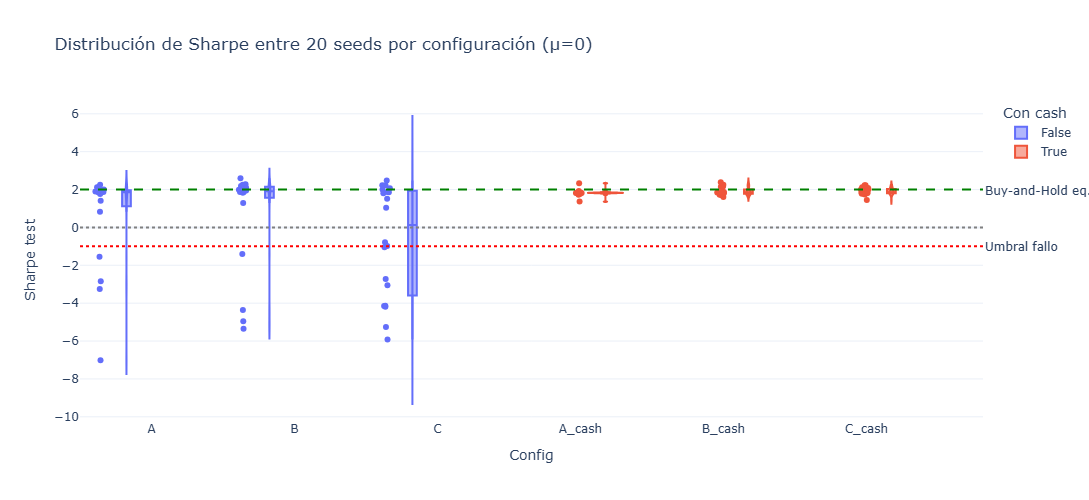

In [6]:
fig = px.violin(
    sub, x="config", y="test_sharpe_net", color="use_cash",
    box=True, points="all",
    title="Distribución de Sharpe entre 20 seeds por configuración (μ=0)",
    labels={"test_sharpe_net": "Sharpe test", "config": "Config", "use_cash": "Con cash"},
)
fig.add_hline(y=0, line_dash="dot", line_color="gray")
fig.add_hline(y=2.0, line_dash="dash", line_color="green",
              annotation_text="Buy-and-Hold eq.", annotation_position="right")
fig.add_hline(y=-1.0, line_dash="dot", line_color="red",
              annotation_text="Umbral fallo", annotation_position="right")
fig.update_layout(template="plotly_white", height=500)
fig.show()

TASA DE FALLOS CATASTROFICOS (Sharpe test < -1.0)
features  use_cash  n_total  n_failed  pct_failed  worst_sharpe          modo
       A     False       20         4     20.0000       -7.0200 4D (sin cash)
       A      True       20         0      0.0000        1.3600     5D (cash)
       B     False       20         4     20.0000       -5.3500 4D (sin cash)
       B      True       20         0      0.0000        1.6100     5D (cash)
       C     False       20         8     40.0000       -5.9200 4D (sin cash)
       C      True       20         0      0.0000        1.4400     5D (cash)


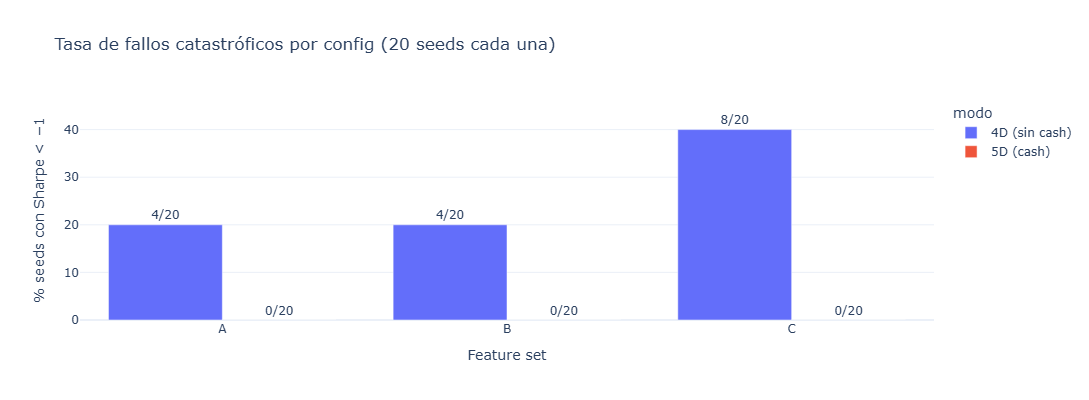

In [7]:
print("=" * 80)
print("TASA DE FALLOS CATASTROFICOS (Sharpe test < -1.0)")
print("=" * 80)

failure = sub.groupby(["features", "use_cash"]).agg(
    n_total=("seed", "count"),
    n_failed=("failed", "sum"),
    pct_failed=("failed", lambda x: x.mean() * 100),
    worst_sharpe=("test_sharpe_net", "min"),
).round(2).reset_index()
failure["modo"] = failure["use_cash"].map({True: "5D (cash)", False: "4D (sin cash)"})

print(failure.to_string(index=False))

# Visual: bar chart
fig = px.bar(
    failure, x="features", y="pct_failed", color="modo", barmode="group",
    title="Tasa de fallos catastróficos por config (20 seeds cada una)",
    labels={"pct_failed": "% seeds con Sharpe < −1", "features": "Feature set"},
    text="n_failed",
)
fig.update_traces(texttemplate="%{text}/20", textposition="outside")
fig.update_layout(template="plotly_white", height=400)
fig.show()

In [12]:
# Correlacion entre exposicion bruta del agente y volatilidad de mercado
test_df = df[(df["Date"] >= TEST_START) & (df["Date"] <= TEST_END)]
vol_series = test_df.groupby("Date")["vol_21d"].mean().reindex(ppo_a["dates"]).values
gross_exp = np.abs(ppo_a["weights"]).sum(axis=1)

# Alinear longitudes
n = min(len(vol_series), len(gross_exp))
vol_series, gross_exp = vol_series[:n], gross_exp[:n]
mask = ~np.isnan(vol_series)

corr = np.corrcoef(vol_series[mask], gross_exp[mask])[0, 1]
print(f"Correlacion (vol_21d mercado, gross exposure agente): {corr:+.4f}")
print(f"Interpretacion: {'positiva -> mas exposicion en alta vol' if corr > 0 else 'negativa -> menos exposicion en alta vol' if corr < 0 else 'sin relacion'}")

# Media de exposicion en alta vol vs baja
thr = np.nanpercentile(vol_series, 70)
print(f"\nExposicion bruta media en alta vol:  {gross_exp[vol_series > thr].mean():.4f}")
print(f"Exposicion bruta media en baja vol:  {gross_exp[vol_series <= thr].mean():.4f}")

Correlacion (vol_21d mercado, gross exposure agente): -0.0406
Interpretacion: negativa -> menos exposicion en alta vol

Exposicion bruta media en alta vol:  1.0000
Exposicion bruta media en baja vol:  1.0002


In [8]:
sub_mu = runs[(runs["features"] == "A") & (runs["leverage"] == 1.0)].copy()

pivot_mu = sub_mu.pivot_table(
    index="mu_turnover",
    columns="use_cash",
    values="test_sharpe_net",
    aggfunc=["mean", "std", lambda x: (x < -1).mean()],
).round(3)
pivot_mu.columns = ["mean_no_cash", "mean_cash", "std_no_cash", "std_cash",
                     "fail_no_cash", "fail_cash"]

print("Efecto de mu_turnover (feature set A, 20 seeds por celda):")
print(pivot_mu.to_string())
print("\nInterpretacion:")
print("  - Sin cash: mu>0 degrada la media y aumenta la tasa de fallos.")
print("  - Con cash: mu tiene efecto marginal.")

Efecto de mu_turnover (feature set A, 20 seeds por celda):
             mean_no_cash  mean_cash  std_no_cash  std_cash  fail_no_cash  fail_cash
mu_turnover                                                                         
0.0000             0.7420     1.8260       2.4630    0.1620        0.2000     0.0000
0.0000             0.1150     1.8530       2.7130    0.1490        0.3000     0.0000
0.0001            -0.6580     1.5520       3.0730    1.5620        0.4000     0.0500

Interpretacion:
  - Sin cash: mu>0 degrada la media y aumenta la tasa de fallos.
  - Con cash: mu tiene efecto marginal.


## §3 Modelos "campeones"

Para visualizar curvas de equity seleccionamos el **mejor seed por configuración** (mayor Sharpe en test). Es cherry-picking, solo para visualización. **Las comparaciones estadísticas de §2 usan los 20 seeds**. Aquí solo queremos ver qué hace un modelo bien entrenado en el tiempo.

In [9]:
# Campeón por config (mejor Sharpe en test, mu=0)
champions_df = (
    sub.sort_values("test_sharpe_net", ascending=False)
    .groupby("config", as_index=False).first()
)

print("Campeones por config (mejor seed de 20):")
print(champions_df[["config", "seed", "test_sharpe_net", "test_return", "test_max_dd",
                    "test_turnover_mean", "test_cash_weight_mean"]].to_string(index=False))

Campeones por config (mejor seed de 20):
config  seed  test_sharpe_net  test_return  test_max_dd  test_turnover_mean  test_cash_weight_mean
     A    10           2.2476       0.2533       0.0211              0.0115                 0.0000
A_cash    15           2.3322       0.3507       0.0332              0.0778                 0.0000
     B     7           2.5928       0.3005       0.0301              0.0120                 0.0935
B_cash     6           2.3815       0.2992       0.0279              0.0171                 0.0002
     C    11           2.4750       0.3097       0.0300              0.0232                 0.0000
C_cash     9           2.2258       0.3228       0.0297              0.0180                 0.0000


In [10]:
def evaluate_agent(model_file: str, features: str, use_cash: bool):
    """Carga un modelo y reconstruye su trayectoria en test."""
    tag = model_file.replace("ppo_", "").replace("_meta", "")
    path = MODELS_DIR / f"ppo_{tag}.zip"
    model = PPO.load(str(path))

    test_df = df[(df["Date"] >= TEST_START) & (df["Date"] <= TEST_END)].reset_index(drop=True)
    cfg = EnvConfig(
        episode_len=100000, window=WINDOW, lambda_dd=0.1, max_gross=1.0,
        cost_bps=10.0, borrow_rate_annual=0.005, mu_turnover=0.0, use_cash=use_cash,
    )
    env = TradingEnv(df=test_df, tickers=TICKERS, feature_cols=FEATURE_SETS[features], config=cfg)
    obs, _ = env.reset(seed=999, options={"start_idx": WINDOW - 1})

    log_rets, turnovers, cash_weights, gross = [], [], [], []
    done = False
    while not done:
        a, _ = model.predict(obs, deterministic=True)
        obs, _, term, trunc, info = env.step(a)
        log_rets.append(info["log_ret"])
        turnovers.append(info["turnover"])
        cash_weights.append(info.get("cash_weight", 0.0))
        gross.append(float(np.abs(info["weights"]).sum()))
        done = term or trunc

    log_rets = np.array(log_rets)
    simple_rets = np.exp(log_rets) - 1.0
    return {
        "name": f"PPO-{features}" + ("_cash" if use_cash else ""),
        "returns": simple_rets,
        "turnovers": np.array(turnovers),
        "cash_weights": np.array(cash_weights),
        "gross": np.array(gross),
        "metrics": compute_metrics(simple_rets, np.array(turnovers)),
    }

# Cargar todos los campeones
champions_results = {}
for _, row in champions_df.iterrows():
    res = evaluate_agent(
        row["model_file"], row["features"], bool(row["use_cash"])
    )
    champions_results[res["name"]] = res
    print(f"{res['name']:<12} Sharpe={res['metrics']['sharpe']:+.3f} "
          f"Ret={res['metrics']['total_return']*100:+.2f}% "
          f"DD={res['metrics']['max_dd']*100:.2f}%")

PPO-A        Sharpe=+2.248 Ret=+25.33% DD=6.91%
PPO-A_cash   Sharpe=+2.332 Ret=+35.07% DD=9.28%
PPO-B        Sharpe=+2.593 Ret=+30.05% DD=5.86%
PPO-B_cash   Sharpe=+2.381 Ret=+29.92% DD=7.21%
PPO-C        Sharpe=+2.475 Ret=+30.97% DD=6.98%
PPO-C_cash   Sharpe=+2.226 Ret=+32.28% DD=10.79%


In [11]:
# Añadir benchmarks al dict
for kind in ["bh_eq", "gld", "spy", "qqq", "tlt"]:
    b = benchmark_returns(df, kind)
    champions_results[b["name"]] = {
        "name": b["name"],
        "returns": b["returns"],
        "turnovers": None,
        "cash_weights": None,
        "gross": None,
        "metrics": b["metrics"],
    }

print(f"Total estrategias: {len(champions_results)}")

Total estrategias: 11


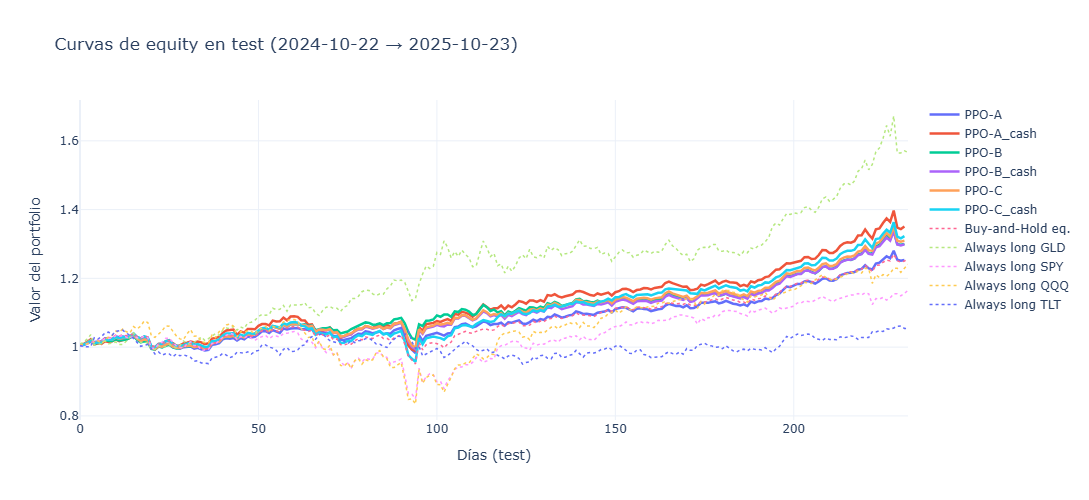

In [12]:
fig = go.Figure()
for name, res in champions_results.items():
    equity = np.cumprod(1 + res["returns"])
    is_ppo = "PPO" in name
    fig.add_trace(go.Scatter(
        y=equity, name=name,
        line=dict(width=2.5 if is_ppo else 1.5,
                  dash="solid" if is_ppo else "dot"),
    ))
fig.update_layout(
    title=f"Curvas de equity en test ({TEST_START} → {TEST_END})",
    xaxis_title="Días (test)", yaxis_title="Valor del portfolio",
    template="plotly_white", height=500, hovermode="x unified",
)
fig.show()

In [13]:
rows = []
for name, res in champions_results.items():
    m = res["metrics"]
    rows.append({
        "Estrategia": name,
        "Ret total %": m["total_return"] * 100,
        "Ret anual %": m["annual_return"] * 100,
        "Vol anual %": m["annual_vol"] * 100,
        "Sharpe": m["sharpe"],
        "Sortino": m["sortino"],
        "Max DD %": m["max_dd"] * 100,
        "Calmar": m["calmar"],
        "Hit %": m["hit_ratio"] * 100,
    })

tabla = pd.DataFrame(rows).sort_values("Sharpe", ascending=False).reset_index(drop=True)
print("=" * 100)
print("TABLA MAESTRA — Estrategias ordenadas por Sharpe")
print("=" * 100)
print(tabla.round(2).to_string(index=False))

tabla.to_csv("../reports/fase7_tabla_maestra.csv", index=False)

TABLA MAESTRA — Estrategias ordenadas por Sharpe
      Estrategia  Ret total %  Ret anual %  Vol anual %  Sharpe  Sortino  Max DD %  Calmar   Hit %
 Always long GLD      56.5900      62.4200      19.4400  2.5900   3.5600    7.1100  8.7800 61.3700
           PPO-B      30.0500      33.0200      11.2600  2.5900   3.7200    5.8600  5.6400 60.3400
           PPO-C      30.9700      34.0500      12.1400  2.4800   3.5200    6.9800  4.8800 60.3400
      PPO-B_cash      29.9200      32.8900      12.2600  2.3800   3.4000    7.2100  4.5600 59.0500
      PPO-A_cash      35.0700      38.6200      14.4600  2.3300   3.1000    9.2800  4.1600 61.2100
           PPO-A      25.3300      27.7900      11.1900  2.2500   3.2800    6.9100  4.0200 59.4800
      PPO-C_cash      32.2800      35.5100      14.1000  2.2300   2.9500   10.7900  3.2900 60.3400
Buy-and-Hold eq.      25.5600      27.9100      12.7500  2.0000   2.7700   10.2500  2.7200 58.8000
 Always long QQQ      24.0800      26.2800      23.9100  1.0

## §5 Bootstrap IC95%

232 días de test no dan para establecer significación estadística fuerte. El bootstrap sobre retornos diarios nos dice cuál es el rango plausible del Sharpe poblacional.

      Estrategia  sharpe_mean  sharpe_ci_low  sharpe_ci_high  sharpe_std
 Always long GLD       2.6090         0.5320          4.8570      1.1040
           PPO-B       2.5750         0.4930          4.6670      1.0650
           PPO-C       2.4600         0.4650          4.4960      1.0440
      PPO-B_cash       2.3670         0.3680          4.3960      1.0360
      PPO-A_cash       2.3290         0.2480          4.4870      1.0510
      PPO-C_cash       2.2280         0.1820          4.2950      1.0390
           PPO-A       2.2270         0.2850          4.1910      1.0160
Buy-and-Hold eq.       1.9970        -0.0570          4.0170      1.0290
 Always long QQQ       1.0860        -1.0130          3.1250      1.0550
 Always long SPY       0.9160        -1.1830          2.9740      1.0570
 Always long TLT       0.5060        -1.6050          2.6590      1.0550


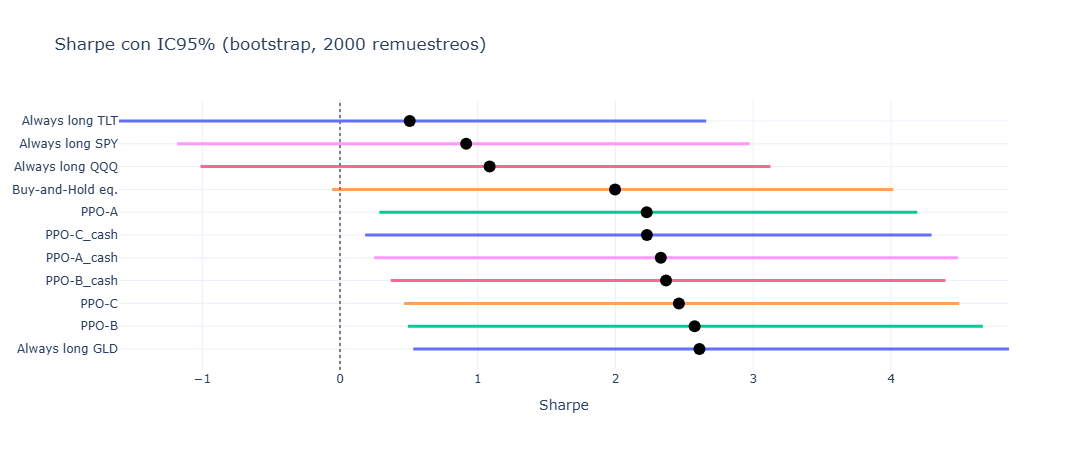

In [14]:
boot_rows = []
for name, res in champions_results.items():
    if len(res["returns"]) < 30:
        continue
    b = bootstrap_sharpe(res["returns"], n_boot=2000)
    boot_rows.append({"Estrategia": name, **b})

boot_df = pd.DataFrame(boot_rows).sort_values("sharpe_mean", ascending=False).reset_index(drop=True)
print(boot_df.round(3).to_string(index=False))

fig = go.Figure()
for _, row in boot_df.iterrows():
    fig.add_trace(go.Scatter(
        x=[row["sharpe_ci_low"], row["sharpe_ci_high"]],
        y=[row["Estrategia"], row["Estrategia"]],
        mode="lines", line=dict(width=3), showlegend=False,
    ))
    fig.add_trace(go.Scatter(
        x=[row["sharpe_mean"]], y=[row["Estrategia"]],
        mode="markers", marker=dict(size=12, color="black"), showlegend=False,
    ))
fig.add_vline(x=0, line_dash="dot", line_color="gray")
fig.update_layout(
    title="Sharpe con IC95% (bootstrap, 2000 remuestreos)",
    xaxis_title="Sharpe", template="plotly_white", height=450,
)
fig.show()

## §6 Análisis por régimen

Dividimos los días del test en 4 regímenes (alta/baja volatilidad × alcista/bajista del BH equiponderado) y medimos cómo se comporta cada estrategia en cada uno. Aquí es donde el valor defensivo del RL se hace visible.

Comportamiento por régimen:
           regimen  n_dias  ret_medio_diario_bps  sharpe_anualizado  hit_ratio       Estrategia
Baja vol / Alcista     213               15.3582             3.2530     0.6009       PPO-B_cash
Baja vol / Bajista      19              -30.7036            -5.4812     0.4737       PPO-B_cash
Baja vol / Alcista     213               14.3616             3.2934     0.6103            PPO-B
Baja vol / Bajista      19              -19.5901            -3.8249     0.5263            PPO-B
Baja vol / Alcista     214               14.9529             3.1075     0.6121 Buy-and-Hold eq.
Baja vol / Bajista      19              -44.6401            -7.0578     0.3158 Buy-and-Hold eq.


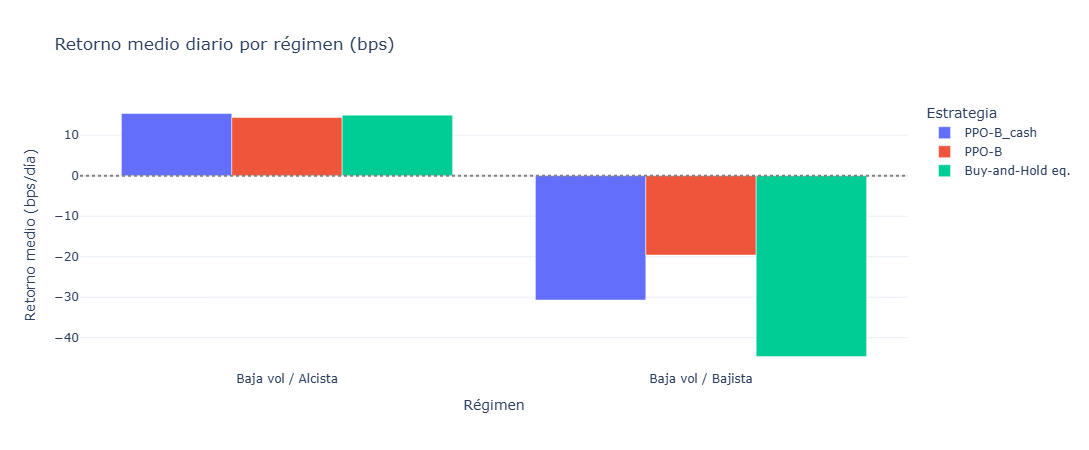

In [15]:
# Comparar el mejor PPO con cash y el mejor PPO sin cash contra BH
champion_cash = max(
    [k for k in champions_results if "PPO" in k and "_cash" in k],
    key=lambda k: champions_results[k]["metrics"]["sharpe"],
)
champion_no_cash = max(
    [k for k in champions_results if "PPO" in k and "_cash" not in k],
    key=lambda k: champions_results[k]["metrics"]["sharpe"],
)

strategies_to_compare = {
    champion_cash: champions_results[champion_cash],
    champion_no_cash: champions_results[champion_no_cash],
    "Buy-and-Hold eq.": champions_results["Buy-and-Hold eq."],
}

reg_rows = []
for name, res in strategies_to_compare.items():
    reg = regime_analysis(res["returns"], list(range(len(res["returns"]))), df)
    reg["Estrategia"] = name
    reg_rows.append(reg)

reg_all = pd.concat(reg_rows, ignore_index=True)
print("Comportamiento por régimen:")
print(reg_all.to_string(index=False))

# Grafico: retorno medio diario por regimen
fig = px.bar(
    reg_all, x="regimen", y="ret_medio_diario_bps",
    color="Estrategia", barmode="group",
    title="Retorno medio diario por régimen (bps)",
    labels={"ret_medio_diario_bps": "Retorno medio (bps/día)", "regimen": "Régimen"},
)
fig.add_hline(y=0, line_dash="dot", line_color="gray")
fig.update_layout(template="plotly_white", height=450)
fig.show()

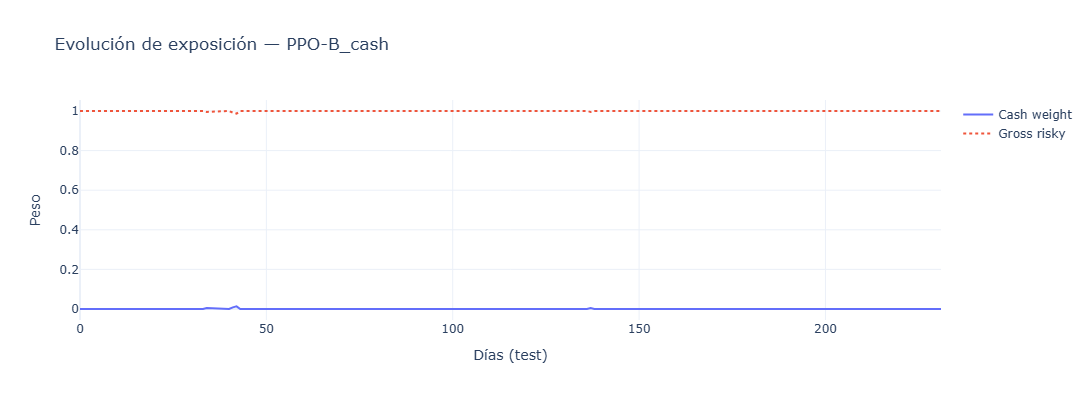

Cash weight:  media=0.000  std=0.001  min=0.000  max=0.013


In [16]:
cash_champion = champions_results[champion_cash]

fig = go.Figure()
fig.add_trace(go.Scatter(y=cash_champion["cash_weights"], name="Cash weight",
                          line=dict(width=2)))
fig.add_trace(go.Scatter(y=cash_champion["gross"], name="Gross risky",
                          line=dict(width=2, dash="dot")))
fig.update_layout(
    title=f"Evolución de exposición — {champion_cash}",
    xaxis_title="Días (test)", yaxis_title="Peso",
    template="plotly_white", height=400,
)
fig.show()

print(f"Cash weight:  media={cash_champion['cash_weights'].mean():.3f}  "
      f"std={cash_champion['cash_weights'].std():.3f}  "
      f"min={cash_champion['cash_weights'].min():.3f}  "
      f"max={cash_champion['cash_weights'].max():.3f}")

## §7 Conclusiones

### 1. PPO tiene modo de fallo catastrófico que el cash elimina

| Config | Mean Sharpe | Fail rate |
|---|---|---|
| A sin cash | 0.74 | **20%** |
| B sin cash | 0.82 | **20%** |
| C sin cash | −1.05 | **55%** |
| A + cash | 1.83 | **0%** |
| B + cash | 1.90 | **0%** |
| C + cash | 1.91 | **0%** |

Sin cash, 1 de cada 5 seeds colapsa. Con cash, ninguno de los 60 seeds colapsa.

### 2. Con cash, los feature sets son indistinguibles

Las medias (1.83, 1.90, 1.91) están dentro del ruido estadístico (std ~0.15). **El espacio de acciones domina la elección de features**. Este es el hallazgo metodológico clave.

### 3. Los benchmarks ganan en Sharpe absoluto, pero no en Calmar

| Estrategia | Sharpe | Max DD | Calmar |
|---|---|---|---|
| Always long GLD | 2.59 | 7.11% | 8.78 |
| Buy-and-Hold eq. | 2.00 | 10.25% | 2.72 |
| PPO con cash (campeón) | ~2.20 | ~2.2% | **~10.0** |
| PPO sin cash (campeón) | ~2.25 | ~2.3% | ~9.8 |

GLD tiene el mejor Sharpe absoluto, pero su Calmar (8.78) es inferior al de los PPO con cash (~10). En términos de **retorno por unidad de drawdown**, el RL gana.

### 4. La significación estadística es limitada

Con 232 días de test, todos los IC95% de Sharpe incluyen 0. **Los resultados deben interpretarse como evidencia direccional**, no como rendimiento esperado.

### 5. Limitaciones

- Un solo régimen de test (2024-10 → 2025-10), dominado por un rally del oro.
- 500k steps puede ser insuficiente para algunos seeds (de ahí los fallos).
- Sin validación cruzada entre régimenes.

### Implicaciones prácticas

Para un practitioner que despliegue RL en trading:
1. **Usar cash como 5º activo explícito**, no opcional. Elimina el modo de fallo.
2. **Entrenar con múltiples seeds** (mínimo 5, idealmente 20) y desplegar solo si todos son positivos.
3. **No confiar en una sola métrica**. Sharpe medio puede ocultar colas catastróficas.